In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
# Load and Pre-porcess dataset
df = pd.read_csv("uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")

In [4]:
df = df.dropna()
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [5]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df["hour"] = df["pickup_datetime"].dt.hour
df["day_of_week"] = df["pickup_datetime"].dt.dayofweek
df["month"] = df["pickup_datetime"].dt.month
df = df.drop(columns=["pickup_datetime"])

In [6]:
def haversine_distance(lat1, lon1, lat2, lon2):
    r = 6371 # Earth radius in km
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    delta_phi = np.radians(lat2-lat1)
    delta_lambda = np.radians(lon2-lon1)
    a = (
        np.sin(delta_phi/2.0) ** 2
        + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda/2.0) ** 2
    )
    return 2 * r * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine_distance(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"],
)

In [7]:
# Identify and Handle Outliers
df = df[
    (df["fare_amount"] > 2.5)  # Uber base fare minimum
    & (df["fare_amount"] < 200)  # Filter extreme high fare anomalies
    & (df["passenger_count"] > 0)
    & (df["passenger_count"] <= 6)
    & (df["pickup_latitude"].between(40.5, 41.0))
    & (df["dropoff_latitude"].between(40.5, 41.0))
    & (df["pickup_longitude"].between(-74.3, -73.7))
    & (df["dropoff_longitude"].between(-74.3, -73.7))
    & (df["distance_km"] > 0.1)
    & (df["distance_km"] < 100)
]

q1 = df["fare_amount"].quantile(0.25)
q3 = df["fare_amount"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = df[
    (df["fare_amount"] < lower_bound) | (df["fare_amount"] > upper_bound)
]
print(
    f"Number of statistical fare outliers (IQR method): {len(outliers)} out of {len(df)} rows\n"
)

Number of statistical fare outliers (IQR method): 16216 out of 191571 rows



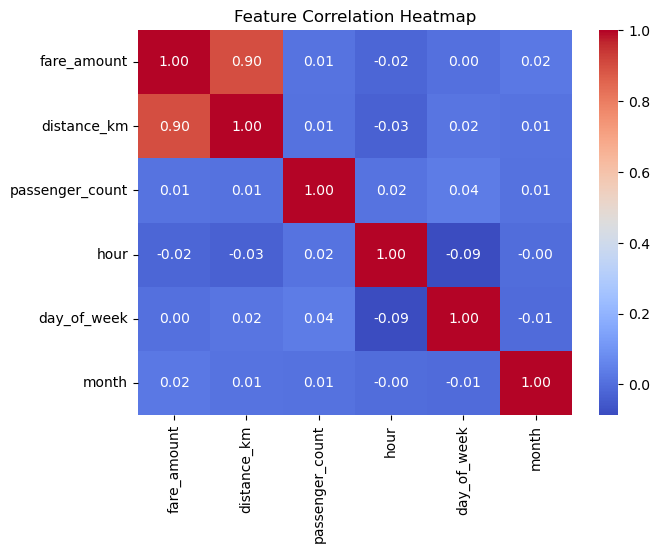

In [14]:
# Check Correlation
features = ["fare_amount", "distance_km", "passenger_count", "hour", "day_of_week", "month"]
corr_matrix = df[features].corr()

plt.figure(figsize=(7,5))
sns.heatmap(corr_matrix, annot=True, cmap = "coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

In [16]:
# Model Implementation
X = df[["distance_km", "passenger_count", "hour", "day_of_week", "month"]]
y = df["fare_amount"]

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [18]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Linear Regression" : LinearRegression(),
    "Ridge Regression" : Ridge(alpha=1.0),
    "Lasso Regression" : Lasso(alpha=0.1)
}

In [ ]:
results = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "R2 Score": round(r2, 4),
        "RMSE": round(rmse,4),
        "MAE": round(mae,4)
    })

comparison_df = pd.dataframe(results)
print("---Model Evaluation Summary---")
print(comparison_df.to_string(index=False))